# NN experiment with direct spectral norms and optional Huber smoothing

This experimental alternative constructs the 2-by-2 input Hessians directly. Both Adam and GLAd use the same configured objective. The separate 337-by-337 parameter Hessian still follows `GLAD_PERIODS`.

**Configure `SPECTRAL_SMOOTHING_EPS` in the first code cell.** With a positive epsilon, the squared spectral norm is replaced by a **Huber upper approximation**. For `A = H @ H`, let `r = sqrt((A[0,0]-A[1,1])**2 + 4*A[0,1]**2)`, the gap between the two squared eigenvalues. Replace `r` by `r**2/(2*epsilon) + epsilon/2` when `r <= epsilon`, and leave `r` unchanged otherwise; the surrogate is `(trace(A) + huber_radius)/2`. It equals the exact squared norm outside this tie band, and exceeds it by at most `epsilon/4` inside. It is C1, generally not C2, with a locally semismooth gradient; the same is true after composition with the squared hinge. Full derivatives are retained and no tie derivative fallback is needed. Other convergence assumptions are not established here.

Set **`SPECTRAL_SMOOTHING_EPS = 0.0`** to restore the unsmoothed exact objective and the previous averaged-derivative tie policy (`exact_norm_module.DEFAULT_TIE_POLICY`). Positive spectral smoothing is different from `POWER_EPS`, which regularizes vector normalization in the paper's power-iteration experiment. Spectral smoothing is a separate surrogate, not Appendix E.1's fixed-power construction. The plotted input-Hessian maximum always uses exact sampled eigenvalues, even when the training penalty is smoothed.

Reference: local manuscript dated 2026-10-22, Section 5.1, equation (26); [arXiv:2602.08069v1](https://arxiv.org/abs/2602.08069v1), equation (27). This notebook is not a reproduction of the published figures. See `CORRECTIONS.md`, `exact_spectral_norm.py`, and `../THIRD_PARTY.txt` for implementation, validation and attribution.

The **first code cell** is authoritative for method selection, budgets, learning rate, penalty, smoothing epsilon, sample count, seeds, precision, solver tolerances and export switches. Samples and weights are generated in float32 with seeds 26/27 then promoted to float64. All methods share their initialization. Runtime and convergence benefits from smoothing must be measured; they are not guaranteed.

**Use a fresh kernel and Run All for a new epsilon.** Changing epsilon changes the objective, so completed unsmoothed runs must not be mixed into a smoothed comparison. `RUN_ADAM=False` skips Adam. `GLAD_PERIODS=[10]` trains only period 10; include 1 explicitly for fresh Hessians. With the objective fixed, change `GLAD_PERIODS` in the first code cell and rerun that cell (or assign the list in a temporary cell), then run the GLAd training and evaluation/export/plot cells to add a method. The first code cell preserves stored results; the data/model setup cell clears them. Review refuses comparisons mixing epsilon or penalty values. For a short smoke run use three updates each.

Figure 1 plots `grad_norm` versus runtime and accepted updates (a selected derivative at ties only in unsmoothed mode). Figure 2 plots `hessian_norm`, the exact sampled maximum. These samples do not certify a global Lipschitz bound. Positive-epsilon results use `corrected_results/huber_spectral_norm/<timestamp>/nn_results_huber.pkl`; zero-epsilon results use the previous `exact_spectral_norm` directory and filenames. Metadata includes epsilon, its squared-norm bias bound and derivative policy.

If an existing kernel reports `unexpected keyword argument 'spectral_smoothing_eps'`, it still holds an older imported helper. The import cell now reloads that module. To repair the current binding without resetting data, settings or stored methods, run this in a temporary cell, then rerun the failed training cell:

```python
import importlib
from NN import exact_spectral_norm as exact_norm_module
exact_norm_module = importlib.reload(exact_norm_module)
exact_hessian_norm_penalty = exact_norm_module.exact_hessian_norm_penalty
```

This reload does not convert old histories to a new objective. Keep epsilon and penalty fixed when reusing completed methods; start a fresh comparison when changing them.


In [115]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  # Retained Windows workaround.

import sys
import importlib
from pathlib import Path
from datetime import datetime
import platform
import pickle
import math
import random
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.func import functional_call
import matplotlib.pyplot as plt

sys.dont_write_bytecode = True
NN_DIR = Path.cwd()
if not (NN_DIR / "GLAdSSNOptimizer_new.py").exists():
    NN_DIR = NN_DIR / "NN"
sys.path.insert(0, str(NN_DIR.parent.resolve()))
from NN.GLAdSSNOptimizer_new import GlAdSSNOptimizer
from NN.utils_new import make_param_vector_interface
from NN import exact_spectral_norm as exact_norm_module
# Jupyter caches imported modules across cell reruns; load the current helper API.
exact_norm_module = importlib.reload(exact_norm_module)
exact_hessian_norm_penalty = exact_norm_module.exact_hessian_norm_penalty

# Experiment configuration (edit settings here).
RUN_ADAM = True  # False skips Adam; stored results remain available.
N = 100  # Training samples.

# Training budgets; measure runtime for the configured smoothing and periods.
SEED, TEST_SEED = 26, 27
ADAM_EPOCHS = 20_000
GLAD_EPOCHS = 15000
GRAD_TARGETS = (1e-2, 1e-3, 1e-4)  # Reporting only; these do not stop training.
ADAM_LR = 5*1e-5
GRAD_TOL = 0.0  # Exact stationarity only; positive values add early stopping.
LAM_MIN = 1e-9  # Numerical damping floor; 0 disables it.
SOLVE_RTOL = 1e-10  # Explicit relative residual; independent of machine epsilon.
MAX_BACKTRACKS = 25  # Up to 26 trials, independent of the Hessian reuse period.
SAVE_RESULTS = True
SAVE_FIGURES = True
DTYPE = torch.float64  # Training and evaluation precision for every method.
INITIALIZATION_DTYPE = torch.float32  # Preserve earlier samples and starting weights.
device = torch.device("cpu")
torch.set_default_dtype(DTYPE)
torch.set_num_threads(1)
torch.manual_seed(SEED)
random.seed(SEED)


GLAD_PERIODS = [200, 500]  # Include 1 explicitly for fresh Hessians; [10] runs only period 10.

penalty_coefficient = 1  # Paper reference uses 1.
SPECTRAL_SMOOTHING_EPS = 5*1e-2  # Huber tie-band width for the squared spectral maximum; 0.0 restores the unsmoothed exact objective.


# Set up regression problem and define neural network

In [116]:
X = torch.rand(N, 2, device=device, dtype=INITIALIZATION_DTYPE) * 2 * math.pi
Y = (
    torch.sin(X[:, 0]) * torch.cos(X[:, 1])
    + 0.2 * torch.sin(2 * X[:, 0] + X[:, 1])
    + 0.1 * X[:, 0] * X[:, 1]
)
Y = Y + 0.05 * torch.randn_like(Y)
Y = Y.unsqueeze(1)
# Promote the same rounded data, rather than drawing a different float64 sample.
X, Y = X.to(dtype=DTYPE), Y.to(dtype=DTYPE)


dataset = list(zip(X, Y))
batch_size = len(dataset)  # full batch


class Net(nn.Module):
    def __init__(self, dtype=DTYPE):
        super().__init__()
        self.fc1 = nn.Linear(2, 16, dtype=dtype)
        self.fc2 = nn.Linear(16, 16, dtype=dtype)
        self.fc3 = nn.Linear(16, 1, dtype=dtype)

    def forward(self, x):
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        return self.fc3(x)


# Snapshot the first network after generating training data (seed 26).
# Every trainer loads these same weights, regardless of its execution order.
initial_state = {
    name: value.detach().to(dtype=DTYPE).clone()
    for name, value in Net(dtype=INITIALIZATION_DTYPE).state_dict().items()
}
all_histories = {}
all_run_info = {}
all_models = {}  # Populated only by the training cells you choose to execute.


# Accuracy estimation

In [117]:
def simulate_dataset(N, device=device, noise_std=0.05, generator=None):
    X = torch.rand(N, 2, device=device, dtype=INITIALIZATION_DTYPE, generator=generator) * 2 * math.pi
    Y = (
        torch.sin(X[:, 0]) * torch.cos(X[:, 1])
        + 0.2 * torch.sin(2 * X[:, 0] + X[:, 1])
        + 0.1 * X[:, 0] * X[:, 1]
    )
    Y = Y + noise_std * torch.randn(Y.shape, device=device, dtype=Y.dtype, generator=generator)
    Y = Y.unsqueeze(1)
    return list(zip(X.to(dtype=DTYPE), Y.to(dtype=DTYPE)))


def evaluate_regression_accuracy(model, dataset_to_test, tolerance=0.001, batch_size=None):
    was_training = model.training
    model.eval()

    if batch_size is None:
        batch_size = len(dataset_to_test)

    total_correct = 0.0
    total_sq_error = 0.0
    total_points = 0

    with torch.no_grad():
        for i in range(0, len(dataset_to_test), batch_size):
            batch = dataset_to_test[i : i + batch_size]
            xb = torch.stack([b[0] for b in batch]).to(device)
            yb = torch.stack([b[1] for b in batch]).to(device)

            pred = model(xb)
            err = pred - yb

            total_correct += (err.abs() <= tolerance).float().sum().item()
            total_sq_error += err.pow(2).sum().item()
            total_points += yb.numel()

    if was_training:
        model.train()

    accuracy = total_correct / total_points
    mse = total_sq_error / total_points
    return accuracy, mse

# One independently seeded test set, reused by every method.
simulated_test_dataset = simulate_dataset(
    N=1000, generator=torch.Generator(device=device).manual_seed(TEST_SEED))


def make_start_model():
    model = Net().to(device)
    model.load_state_dict(initial_state)
    return model.train()


def measure_model(model):
    """Measure loss, full gradient, and max sampled norm at this same point."""
    penalty, max_norm = exact_hessian_norm_penalty(
        model, dict(model.named_parameters()), X,
        coeff=penalty_coefficient, spectral_smoothing_eps=SPECTRAL_SMOOTHING_EPS)
    loss = F.mse_loss(model(X), Y) + penalty
    grads = torch.autograd.grad(loss, tuple(model.parameters()))
    grad_norm = torch.cat([g.reshape(-1) for g in grads]).norm()
    return loss.detach().item(), grad_norm.detach().item(), max_norm.detach().item()

# GLAd-SSN trainer

In [118]:
def train_with_gladssn(
    epochs=50, update_freq=1, lambda0=1.0, m=MAX_BACKTRACKS,
    print_freq=10, return_model=False, symmetrize=True,
):
    model = make_start_model()
    pack, vec_to_param_dict, assign, _ = make_param_vector_interface(model)
    optimizer = GlAdSSNOptimizer(
        model.parameters(), lambda0=lambda0, m=m,
        number_of_steps_to_freeze=update_freq, symmetrize=symmetrize,
        grad_tol=GRAD_TOL, lam_min=LAM_MIN, solve_rtol=SOLVE_RTOL)

    def loss_from_vec(vec):
        params = vec_to_param_dict(vec)
        penalty, _ = exact_hessian_norm_penalty(
            model, params, X, coeff=penalty_coefficient, spectral_smoothing_eps=SPECTRAL_SMOOTHING_EPS)
        return F.mse_loss(functional_call(model, params, X), Y) + penalty

    t0 = time.perf_counter()
    loss, grad, max_norm = measure_model(model)
    loss_list, grad_list, hessian_norm_list = [loss], [grad], [max_norm]
    time_list, lambda_k_list = [time.perf_counter() - t0], [lambda0]
    info = dict(status="iterations_exceeded", accepted_steps=0, step_diagnostics=[], spectral_smoothing_eps=SPECTRAL_SMOOTHING_EPS, spectral_smoothing="huber" if SPECTRAL_SMOOTHING_EPS > 0 else "none", penalty_coefficient=penalty_coefficient)

    for epoch in range(epochs):
        _, _, next_coefficient = optimizer.step(loss_from_vec, pack, assign)
        status = optimizer.state["status"]
        # Scalar diagnostics only; no additional objective or Hessian evaluations.
        info["step_diagnostics"].append(dict(
            attempted_update=epoch + 1, status=status,
            accepted_damping=optimizer.state["accepted_lam"],
            next_coefficient=optimizer.state["lambda_k"],
            trials=optimizer.state["last_trials"],
            relative_linear_residual=optimizer.state["last_linear_residual"],
            hessian_evaluations=optimizer.state["hessian_evaluations"],
            linear_solves=optimizer.state["linear_solves"]))
        if status != "accepted":
            info["status"] = status
            # Preserve the last accepted point, including time spent on failure.
            time_list[-1] = time.perf_counter() - t0
            break
        loss, grad, max_norm = measure_model(model)
        loss_list.append(loss)
        grad_list.append(grad)
        hessian_norm_list.append(max_norm)
        time_list.append(time.perf_counter() - t0)
        lambda_k_list.append(next_coefficient)  # Lambda, not gradient-scaled lambda.
        if print_freq and (epoch + 1) % print_freq == 0:
            print(f"[GLAd-SSN] {epoch + 1}/{epochs}: loss={loss:.6g}, "
                  f"||g||={grad:.3e}, max sampled exact norm={max_norm:.4f}")
        if grad <= GRAD_TOL:
            info["status"] = "converged"
            break

    info.update(accepted_steps=optimizer.state["k"],
                hessian_evaluations=optimizer.state["hessian_evaluations"],
                linear_solves=optimizer.state["linear_solves"],
                last_trials=optimizer.state["last_trials"],
                last_linear_residual=optimizer.state["last_linear_residual"],
                last_damping=optimizer.state["accepted_lam"],
                next_coefficient=optimizer.state["lambda_k"], update_freq=update_freq)
    print(f"GLAd-SSN (period {update_freq}): {info['status']}, {info['accepted_steps']} accepted steps")
    result = (loss_list, time_list, grad_list, hessian_norm_list, lambda_k_list, info)
    return (model, *result) if return_model else result

# Adam trainer

In [119]:
def train_with_adam(
    epochs=20, lr=ADAM_LR, batch_size=None, print_freq=100, return_model=False,
):
    # This notebook compares full-batch methods, as in the paper.
    if batch_size is not None and batch_size != len(dataset):
        raise ValueError("Use full-batch Adam for this comparison")
    model = make_start_model()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="min", factor=0.5, patience=5, threshold=1e-5, min_lr=1e-6)
    t0 = time.perf_counter()
    loss, grad, max_norm = measure_model(model)
    loss_list, grad_list, hessian_norm_list = [loss], [grad], [max_norm]
    time_list = [time.perf_counter() - t0]
    info = dict(status="iterations_exceeded", accepted_steps=0, learning_rates=[], spectral_smoothing_eps=SPECTRAL_SMOOTHING_EPS, spectral_smoothing="huber" if SPECTRAL_SMOOTHING_EPS > 0 else "none", penalty_coefficient=penalty_coefficient)

    for epoch in range(epochs):
        if grad <= GRAD_TOL:
            info["status"] = "converged"
            break
        learning_rate_used = opt.param_groups[0]["lr"]
        opt.zero_grad(set_to_none=True)
        penalty, _ = exact_hessian_norm_penalty(
            model, dict(model.named_parameters()), X,
            coeff=penalty_coefficient, spectral_smoothing_eps=SPECTRAL_SMOOTHING_EPS)
        loss_before = F.mse_loss(model(X), Y) + penalty
        loss_before.backward()
        previous = [p.detach().clone() for p in model.parameters()]
        opt.step()
        # Keep the original scheduler's pre-update loss convention.
        scheduler.step(loss_before.detach().item())

        loss, grad, max_norm = measure_model(model)
        if not all(math.isfinite(value) for value in (loss, grad, max_norm)):
            with torch.no_grad():
                for parameter, value in zip(model.parameters(), previous):
                    parameter.copy_(value)
            info["status"] = "nonfinite_objective_or_gradient"
            time_list[-1] = time.perf_counter() - t0
            break
        loss_list.append(loss)
        grad_list.append(grad)
        hessian_norm_list.append(max_norm)
        time_list.append(time.perf_counter() - t0)
        info["accepted_steps"] += 1
        info["learning_rates"].append(learning_rate_used)
        if print_freq and (epoch + 1) % print_freq == 0:
            print(f"[Adam] {epoch + 1}/{epochs}: loss={loss:.6g}, "
                  f"||g||={grad:.3e}, max sampled exact norm={max_norm:.4f}")

    print(f"Adam: {info['status']}, {info['accepted_steps']} steps")
    result = (loss_list, time_list, grad_list, hessian_norm_list, info)
    return (model, *result) if return_model else result

## Train Adam (optional)

Adam has its own cell. Set `RUN_ADAM=False` in the first code cell to skip it during a fresh **Run All**. When adding a GLAd period in an already initialized kernel, skip this cell entirely; its existing results remain available.


In [120]:
# RUN_ADAM is configured in the first code cell.

all_models = globals().get("all_models", {})
if RUN_ADAM:
    print("Training with Adam...")
    result = train_with_adam(epochs=ADAM_EPOCHS, lr=ADAM_LR, print_freq=10000, return_model=True)
    model_adam = result[0]
    all_models["Adam"] = model_adam
    all_histories["Adam"] = result[1:-1]
    all_run_info["Adam"] = result[-1]
else:
    print("Skipping Adam; any existing Adam result is retained.")


Training with Adam...
[Adam] 10000/20000: loss=0.0328635, ||g||=4.525e-02, max sampled exact norm=1.0957
[Adam] 20000/20000: loss=0.00599765, ||g||=1.452e-03, max sampled exact norm=1.0430
Adam: iterations_exceeded, 20000 steps


## Train selected GLAd periods

**Set `GLAD_PERIODS` in the first code cell, execute that cell, then run the training cell below.** In an initialized kernel you can instead assign `GLAD_PERIODS = [10]` in a temporary cell before running the training cell. `[1, 5, 20, 50]` trains four variants; `[10]` trains only period 10. Period 1 is the fresh-Hessian method and runs only when explicitly listed.

Each selected method starts from the shared initial weights and uses `GLAD_EPOCHS`. Existing methods are retained for comparison; selecting an already stored period replaces only that method's in-memory result. Old timestamped exports are untouched. To add a period, do not rerun the data/model setup cell, since it clears the result dictionaries. After training, run the evaluation/export/plot cells below; they perform no training. For a fresh kernel, use **Run All** with `RUN_ADAM=False` if Adam is not wanted.


In [121]:
# GLAD_PERIODS is configured in the first code cell.

if any(type(period) is not int or period < 1 for period in GLAD_PERIODS):
    raise ValueError("GLAD_PERIODS must contain positive integers")
if len(GLAD_PERIODS) != len(set(GLAD_PERIODS)):
    raise ValueError("List each GLAd period only once")

# Retain only methods from this initialized exact-norm experiment.
for period in GLAD_PERIODS:
    label = "GLAd-SSN" if period == 1 else f"GLAd-SSN m={period}"
    print("Training with", label)
    result = train_with_gladssn(
        epochs=GLAD_EPOCHS, update_freq=period, print_freq=100, return_model=True)
    all_models[label] = result[0]
    all_histories[label] = result[1:-1]
    all_run_info[label] = result[-1]

print("Stored methods:", list(all_histories))


Training with GLAd-SSN m=200
[GLAd-SSN] 100/15000: loss=0.231286, ||g||=2.635e-01, max sampled exact norm=0.6780
[GLAd-SSN] 200/15000: loss=0.12107, ||g||=1.734e-01, max sampled exact norm=1.1026
[GLAd-SSN] 300/15000: loss=0.0349751, ||g||=3.040e-02, max sampled exact norm=1.0946
[GLAd-SSN] 400/15000: loss=0.0289474, ||g||=2.097e-02, max sampled exact norm=1.0808
[GLAd-SSN] 500/15000: loss=0.0194072, ||g||=9.384e-03, max sampled exact norm=1.0578
[GLAd-SSN] 600/15000: loss=0.0179603, ||g||=9.241e-03, max sampled exact norm=1.0798
[GLAd-SSN] 700/15000: loss=0.0133805, ||g||=8.200e-03, max sampled exact norm=1.0570
[GLAd-SSN] 800/15000: loss=0.0125706, ||g||=6.518e-03, max sampled exact norm=1.0538
[GLAd-SSN] 900/15000: loss=0.0116792, ||g||=4.826e-03, max sampled exact norm=1.0555
[GLAd-SSN] 1000/15000: loss=0.0112844, ||g||=4.641e-03, max sampled exact norm=1.0534
[GLAd-SSN] 1100/15000: loss=0.0105866, ||g||=3.418e-03, max sampled exact norm=1.0384
[GLAd-SSN] 1200/15000: loss=0.010335,

## Review stored results

The cells below evaluate, export and plot the stored models without retraining them. They support any selected GLAd periods, with or without Adam or period 1. Keep the data, initial weights, precision and penalty coefficient fixed when adding methods to a comparison; otherwise start a separate experiment.


In [122]:
# Changing epsilon changes the objective; reject mixed comparisons.
for label, info in all_run_info.items():
    if info.get("spectral_smoothing", "none") != ("huber" if SPECTRAL_SMOOTHING_EPS > 0 else "none") or info.get("spectral_smoothing_eps", 0.0) != SPECTRAL_SMOOTHING_EPS or info.get("penalty_coefficient", penalty_coefficient) != penalty_coefficient:
        raise ValueError("Stored methods use different epsilon/penalty settings. Start a fresh comparison before exporting or plotting.")

trained_models = [(label, all_models[label]) for label in all_histories]
if not trained_models:
    raise ValueError("No trained models available; run Adam or at least one selected GLAd period")
print("Methods included in evaluation and export:", [label for label, _ in trained_models])


Methods included in evaluation and export: ['Adam', 'GLAd-SSN m=200', 'GLAd-SSN m=500']


## Export stored results

Each execution writes to a new timestamped directory. The exported period list describes the methods actually stored, including retained earlier runs.


In [123]:
# New results have their own directory; original data and PDFs are never overwritten.
spectral_mode = "huber" if SPECTRAL_SMOOTHING_EPS > 0 else "exact"
output_dir = None
if SAVE_RESULTS or SAVE_FIGURES:
    output_dir = NN_DIR / "corrected_results" / f"{spectral_mode}_spectral_norm" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    output_dir.mkdir(parents=True, exist_ok=False)

plot_histories = {}
for label, history in all_histories.items():
    saved = {key: list(history[i]) for i, key in enumerate(
        ("loss", "time", "grad_norm", "hessian_norm"))}
    if len(history) > 4:
        saved["Lambda"] = list(history[4])
    plot_histories[label] = saved

# First observed crossing, with no interpolation and no extrapolation.
gradient_target_results = {}
for label, history in plot_histories.items():
    gradient_target_results[label] = {}
    for target in GRAD_TARGETS:
        hit = next((i for i, value in enumerate(history["grad_norm"]) if value <= target), None)
        gradient_target_results[label][f"{target:.0e}"] = dict(
            reached=hit is not None, updates=hit,
            seconds=history["time"][hit] if hit is not None else None)

trained_models = [(label, all_models[label]) for label in all_histories]

run_metadata = dict(
    reference="Local manuscript 2026-10-22, equation (26), Section 5.1 / Appendix E.1 / Table 2",
    public_reference="https://arxiv.org/abs/2602.08069v1 (equation 27; older settings)",
    python=platform.python_version(), torch=torch.__version__, platform=platform.platform(),
    processor=platform.processor(), device=str(device), precision=str(DTYPE),
    threads=torch.get_num_threads(), seed=SEED, test_seed=TEST_SEED,
    initialization_precision=str(INITIALIZATION_DTYPE),
    data_generation="Generate samples, targets and initial weights in float32, then cast to training precision",
    gradient_targets=list(GRAD_TARGETS),
    adam_scheduler="ReduceLROnPlateau per update on pre-update loss; factor .5, patience 5, threshold 1e-5, min_lr 1e-6",
    N=N, noise_std=0.05, architecture=[2,16,16,1], activation="tanh",
    penalty_coefficient=penalty_coefficient, K=None,
    objective=f"{spectral_mode}_sampled_spectral_norm",
    spectral_smoothing_eps=SPECTRAL_SMOOTHING_EPS,
    squared_norm_upper_bias_bound=SPECTRAL_SMOOTHING_EPS/4,
    spectral_smoothing="huber" if SPECTRAL_SMOOTHING_EPS > 0 else "none",
    norm_method="huber_2x2_squared_maximum" if SPECTRAL_SMOOTHING_EPS > 0 else "torch.linalg.eigvalsh",
    active_tie_relative_tolerance=64*torch.finfo(DTYPE).eps,
    active_tie_policy="not_used_with_smoothing" if SPECTRAL_SMOOTHING_EPS > 0 else exact_norm_module.DEFAULT_TIE_POLICY,
    adam_epochs=ADAM_EPOCHS, glad_epochs=GLAD_EPOCHS, adam_lr=ADAM_LR,
    grad_tol=GRAD_TOL, lam_min=LAM_MIN, max_backtracks=MAX_BACKTRACKS,
    solve_rtol=SOLVE_RTOL if SOLVE_RTOL is not None else 100*torch.finfo(DTYPE).eps,
    lazy_periods=[all_run_info[label]["update_freq"] for label in all_histories if label != "Adam"],
    requested_glad_periods=list(GLAD_PERIODS),
    adam_included="Adam" in all_histories,
    derivative=("Full derivatives of Huber squared-norm surrogate" if SPECTRAL_SMOOTHING_EPS > 0
                else "Full derivatives away from active ties; averaged squared-eigenvalue derivatives at flagged ties"),
    regularity=("C1 squared-hinge objective with locally semismooth gradient; other theorem assumptions not established"
                if SPECTRAL_SMOOTHING_EPS > 0 else "Exact norm may be non-C1 at active ties; tie curvature is an explicit approximation"),
    norm_metric="Exact maximum sampled input-Hessian spectral norm (not a global bound)",
    logging="Initial point plus returned iterates; loss, gradient and norm at the same point",
    timing="CPU perf_counter wall time, including diagnostics; model construction excluded")
if SAVE_RESULTS:
    with (output_dir / f"nn_results_{spectral_mode}.pkl").open("wb") as result_file:
        pickle.dump(dict(histories=plot_histories, labels=list(all_histories),
                         metadata=run_metadata, statuses=all_run_info,
                         gradient_targets=gradient_target_results,
                         final_model_states={label: {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                                             for label, model in trained_models},
                         initial_state={k:v.cpu() for k,v in initial_state.items()},
                         training_inputs=X.cpu(), training_targets=Y.cpu(),
                         test_dataset=simulated_test_dataset), result_file)
    print("Saved spectral-norm experiment data to", output_dir)
print("Run statuses:", {label: info["status"] for label, info in all_run_info.items()})

Saved spectral-norm experiment data to c:\Users\cleme\Desktop\Github Repos\skip-the-hessian-keep-the-rates\NN\corrected_results\huber_spectral_norm\20261106_005855_082041
Run statuses: {'Adam': 'iterations_exceeded', 'GLAd-SSN m=200': 'iterations_exceeded', 'GLAd-SSN m=500': 'iterations_exceeded'}


# Code for plotting

In [124]:
# Stable colors for the usual methods; extra periods work without a fixed list size.
known_styles = {
    "Adam": ("#E8601C", "None"),
    "GLAd-SSN": ("#9B8AC4", "^"),
    "GLAd-SSN m=5": ("#88A5DD", "D"),
    "GLAd-SSN m=20": ("#8DCBE4", "x"),
    "GLAd-SSN m=50": ("#C2E3D2", "v"),
    "GLAd-SSN m=100": ("#DDECBF", "h"),
    "GLAd-SSN m=1000": ("#F2E1D0", "1"),
}
labels = list(all_histories)
styles = [known_styles.get(label, (plt.get_cmap("tab20")(i % 20), "o"))
          for i, label in enumerate(labels)]
colors = [color for color, marker in styles]
marker_cycle = [marker for color, marker in styles]
line_widths = [1.0] * len(labels)
line_styles = ["-"] * len(labels)


In [125]:
print(all_histories.keys())



dict_keys(['Adam', 'GLAd-SSN m=200', 'GLAd-SSN m=500'])


# Plot graphs

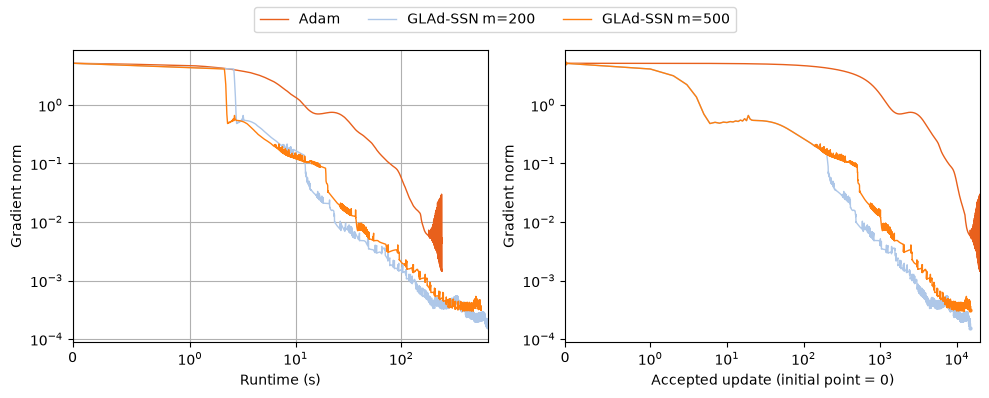

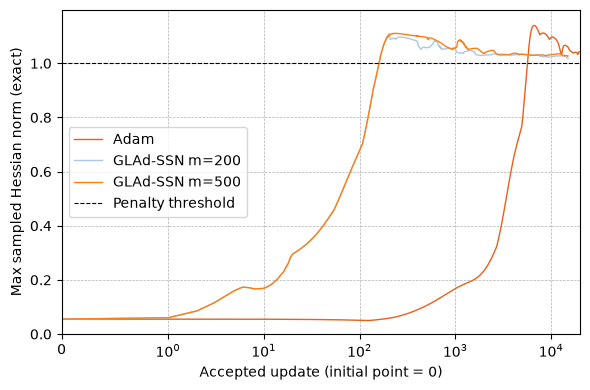

In [126]:
from matplotlib import axes


def plot_graphs(
    list_of_times,
    list_of_grads,
    list_of_labels,
    number_of_methods,
    y_label,
    line_styles,
    which_measure
):
    if number_of_methods is None:
        number_of_methods = len(list_of_times)
    marker_size = 2
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # 2x2 grid
    axes = axes.flatten()  # turn into a simple list: axes[0], axes[1], axes[2], axes[3]
    for i in range(number_of_methods):
        # if labels[i] == "Adam":
            # skip Adam
            # continue
        axes[0].plot(
            list_of_times[i],
            list_of_grads[i],
            label=list_of_labels[i],
            color=colors[i],
            linewidth=1,
            linestyle=line_styles[i],
            # marker=marker_cycle[i],
            markersize=2*marker_size,
            markevery=15000,
        )
    axes[0].set_yscale("symlog", linthresh=1e-12)  # Show exact zeros.
    axes[0].set_xlabel("Runtime (s)")
    axes[0].set_ylabel(y_label)
    axes[0].set_xscale("symlog", linthresh=1)
    axes[0].set_xlim(0, max(max(values) for values in list_of_times))
    # axes[0].legend()
    axes[0].grid(True)

    # Now plot epoch vs grad norm
    # plt.subplot(1, 2, 2)
    for i in range(number_of_methods):
        axes[1].plot(
            list_of_grads[i],
            label=list_of_labels[i],
            color=colors[i],
            # linewidth=line_widths[i],
            linewidth=1,
            linestyle=line_styles[i],
            marker=marker_cycle[i],
            markersize=marker_size,
            markevery=15000,
        )
    axes[1].set_yscale("symlog", linthresh=1e-12)
    axes[1].set_xlabel("Accepted update (initial point = 0)")
    axes[1].set_ylabel(y_label)
    axes[1].set_xscale("symlog", linthresh=1)
    axes[1].set_xlim(0, max(len(values) - 1 for values in list_of_grads))
    # Shared legend
    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="upper center", ncol=3)

    # Reserve space for every legend row when several periods are compared.
    legend_rows = math.ceil(len(handles) / 3)
    fig.tight_layout(rect=[0, 0, 1, max(0.55, 1 - 0.08 * legend_rows)])
    if SAVE_FIGURES:
        plt.savefig(output_dir / (f"plot_NN_{spectral_mode}_" + which_measure + ".pdf"))
    plt.show()
    plt.close()

def plot_penalty(
    list_of_times,
    list_of_grads,
    list_of_labels,
    number_of_methods,
    y_label,
    line_styles,
    which_measure
):
    if number_of_methods is None:
        number_of_methods = len(list_of_times)
    marker_size = 2
    plt.figure(figsize=(6, 4))

    for i in range(number_of_methods):
        plt.plot(
            list_of_grads[i],
            label=list_of_labels[i],
            color=colors[i],
            # linewidth=line_widths[i],
            linewidth=1,
            linestyle=line_styles[i],
            # marker=marker_cycle[i],
            markersize=marker_size,
            markevery=15000,
        )
    plt.xscale("symlog", linthresh=1)
    plt.xlim(0, max(len(values) - 1 for values in list_of_grads))
    plt.ylim(0, 1.05 * max(1.0, max(max(values) for values in list_of_grads)))
    plt.axhline(1.0, color="black", linestyle="--", linewidth=0.8, label="Penalty threshold")
    plt.xlabel("Accepted update (initial point = 0)")
    plt.ylabel(y_label)
    plt.grid(True, which="both", linestyle="--", linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig(output_dir / (f"plot_NN_{spectral_mode}_" + which_measure + ".pdf"))
    plt.show()
    plt.close()
all_methods = list(all_histories.keys())
times_list = [all_histories[m][1] for m in all_methods]
grads_list = [all_histories[m][2] for m in all_methods]
hess_op_norm_list = [all_histories[m][3] for m in all_methods]
lambdas_list = [all_histories[m][4] for m in all_methods if m != "Adam"]

without_adam_times_list = [all_histories[m][1] for m in all_methods if m != "Adam"]


plot_graphs(
    times_list,
    grads_list,
    all_methods,
    None,
    "Gradient norm" if SPECTRAL_SMOOTHING_EPS > 0 else "Derivative norm",
    line_styles,
    which_measure="grad_norm",
)
plot_penalty(
    times_list,
    hess_op_norm_list,
    all_methods,
    None,
    "Max sampled Hessian norm (exact)",
    line_styles,
    which_measure="hess_op_norm",
)


## Train and test comparison

Compare the final trained models on the same training and test samples. **MSE** is the mean squared prediction error, excluding the penalty (lower is better). **Accuracy** is the fraction of predictions within 0.10 of the target (higher is better).

**Runtime (s)** is the recorded total training time, including training diagnostics and excluding this final evaluation.

Run the cell below after training; it only evaluates the existing models. These are results at each method's configured update budget.

In [127]:
from IPython.display import Markdown, display

comparison_models = [(label, all_models[label]) for label in all_histories]

comparison_results = {}
table_lines = [
    "| Method | Train MSE | Test MSE | Train accuracy | Test accuracy | Runtime (s) |",
    "| :--- | ---: | ---: | ---: | ---: | ---: |",
]
for method, trained_model in comparison_models:
    train_accuracy, train_mse = evaluate_regression_accuracy(
        trained_model, dataset, tolerance=0.10, batch_size=batch_size)
    test_accuracy, test_mse = evaluate_regression_accuracy(
        trained_model, simulated_test_dataset, tolerance=0.10, batch_size=batch_size)
    runtime_s = all_histories[method][1][-1]  # Last cumulative training time.
    comparison_results[method] = dict(
        train_mse=train_mse, test_mse=test_mse,
        train_accuracy=train_accuracy, test_accuracy=test_accuracy, runtime_s=runtime_s)
    table_lines.append(
        f"| {method} | {train_mse:.6f} | {test_mse:.6f} | "
        f"{train_accuracy:.1%} | {test_accuracy:.1%} | {runtime_s:.2f} |")

display(Markdown("\n".join(table_lines)))

| Method | Train MSE | Test MSE | Train accuracy | Test accuracy | Runtime (s) |
| :--- | ---: | ---: | ---: | ---: | ---: |
| Adam | 0.005876 | 0.016260 | 77.0% | 61.1% | 241.64 |
| GLAd-SSN m=200 | 0.002652 | 0.010287 | 96.0% | 71.4% | 654.00 |
| GLAd-SSN m=500 | 0.003464 | 0.011140 | 92.0% | 66.8% | 565.82 |

## Time to common derivative targets

Compare the first recorded iterate reaching each target for the same configured spectral-norm objective. An entry is **seconds / accepted updates**; **not reached** means the method did not attain that target within its configured budget. First crossings can be transient, especially for oscillating gradients; inspect the full curves and final values as well. These targets do not change either method's stopping rule.

With positive smoothing epsilon these are ordinary gradient norms. In unsmoothed mode, flagged ties use the selected derivative.


In [128]:
target_columns = [f"{target:.0e}" for target in GRAD_TARGETS]
target_lines = [
    "| Method | " + " | ".join(target_columns) + " |",
    "| :--- | " + " | ".join(["---:"] * len(target_columns)) + " |",
]
for label, entries in gradient_target_results.items():
    values = []
    for column in target_columns:
        entry = entries[column]
        values.append(f"{entry['seconds']:.2f} s / {entry['updates']}" if entry['reached'] else "not reached")
    target_lines.append("| " + label + " | " + " | ".join(values) + " |")
display(Markdown("\n".join(target_lines)))


| Method | 1e-02 | 1e-03 | 1e-04 |
| :--- | ---: | ---: | ---: |
| Adam | 156.31 s / 13021 | not reached | not reached |
| GLAd-SSN m=200 | 23.34 s / 482 | 118.16 s / 2601 | not reached |
| GLAd-SSN m=500 | 37.45 s / 1023 | 168.20 s / 4501 | not reached |